In [1]:
import numpy as np 
import matplotlib.pyplot as plt
from tdmclient import ClientAsync, aw

import Vision
import kalman_filter

In [2]:
client = ClientAsync()
node = aw(client.wait_for_node())
await node.lock()

Node eeecc8f0-055d-414f-a168-42c3ba3a5cd9

In [5]:
async def set_speed(left, right):
    await node.set_variables({
        "motor.left.target": [int(left)],
        "motor.right.target": [int(right)]
    })
    
async def run(left, right, T):
    try:
        await set_speed(left, right)
        await client.sleep(T)          
    finally:
        await set_speed(0, 0)

## Thymio stuff :

In [6]:
v = 300
T = 1 # [s]

await run(v, v, T)

Conversion ratio :  0.3201767676767677


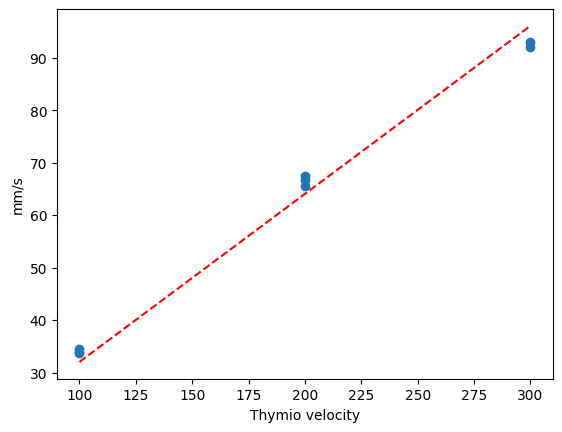

In [36]:
# assess speed conversion


logs = []
#logs.append([v, d]) [thymio, mm]

logs.append([100, 69/2])
logs.append([200, 135/2])
logs.append([300, 186/2])
logs.append([100, 102/3])
logs.append([200, 200/3])
# logs.append([300, 254/3])
logs.append([100, 135/4])
logs.append([200, 262/4])
logs.append([300, 368/4])


logs = np.array(logs)
v_thymio, v_real = logs[:, 0], logs[:, 1]
plt.scatter(logs[:, 0], logs[:, 1])
plt.xlabel("Thymio velocity")
plt.ylabel("mm/s")

rate = (v_thymio @ v_real) / (v_thymio @ v_thymio)
print("Conversion ratio : ", rate)


plt.plot([100, 300], [100*rate, 300*rate], c="red", linestyle="--")
plt.show()

In [15]:
# fix conversion ratio 

SPEED_TO_MM_S = 0.35

In [66]:
# estimate wheel base
     
s = 100
T = 2 # [s]

await run(-s, s, T)

In [ ]:
def get_wheel_base(s, T, N):
    angle = 2*np.pi * N
    return 2*SPEED_TO_MM_S*s*T / angle

In [1]:
logs = [] # count turns done (with fraction)
#logs.append(get_wheel_base(s, T, ...))

# logs.append(get_wheel_base(100, 2, ))


In [8]:
# wheel base 

WHEEL_BASE = 95

In [27]:
# estimate Q - Linear

v = 300
T_lin = 2
pred_along = SPEED_TO_MM_S * T_lin * v

await run(v, v, T_lin)
print(pred_along)

210.0


In [28]:
along = [] # difference between predicted and measured / T_lin

# for v = 100
along.append((17.5-19)/0.5)
along.append((35-35)/1)
along.append((52.5-53)/1.5)
along.append((70-69)/2)

# for v = 200
along.append((35-39)/0.5)
along.append((70-70)/1)
along.append((105-100)/1.5)
along.append((140-134)/2)

# for v = 300
along.append((52.5-54)/0.5)
along.append((105-102)/1)
along.append((157-152)/1.5)
along.append((210-194)/2)


In [ ]:
# estimate Q - angular 

s = None
T_ang = None
pred_angle = 2 * SPEED_TO_MM_S * s * T_ang / WHEEL_BASE

await run(-s, s, T_ang)
print(pred_angle)

In [31]:
e_theta = [] # difference between measured and predicted / T_ang

# e_theta.append()

In [34]:
# estimate Q

q_xy = np.var(along, ddof=1) / 2 
# q_th = np.var(e_theta, ddof=1)   
q_th = 0                        
Q_RATE = np.diag([q_xy, q_xy, q_th])

print(Q_RATE)

[[8.30418771 0.         0.        ]
 [0.         8.30418771 0.        ]
 [0.         0.         0.        ]]


## Camera stuff : 

In [ ]:
# measure variance of camera positions for several immobile positions 
# for the robot then take the mean of the variances

In [3]:
def get_camera_pose():

    return Vision.get_current_thymio_pose()
    pass

Obstacles detected: 0


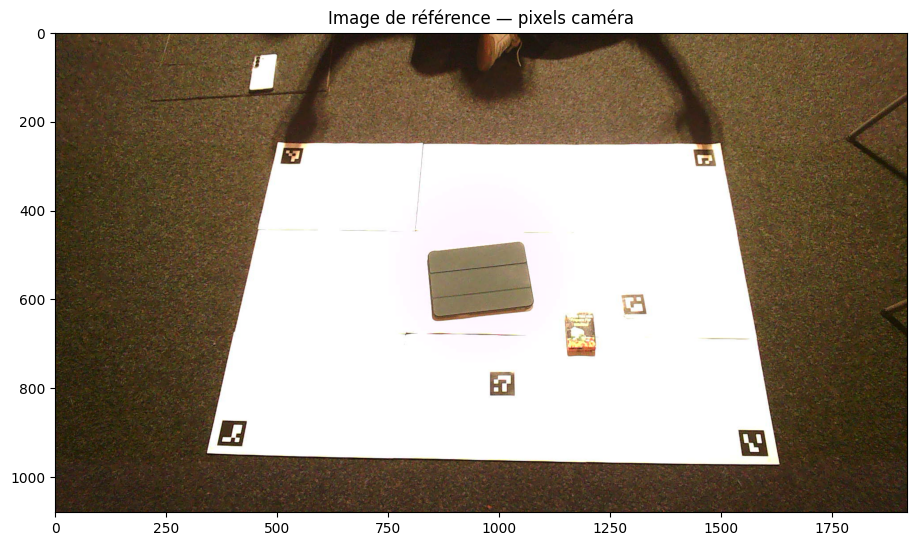

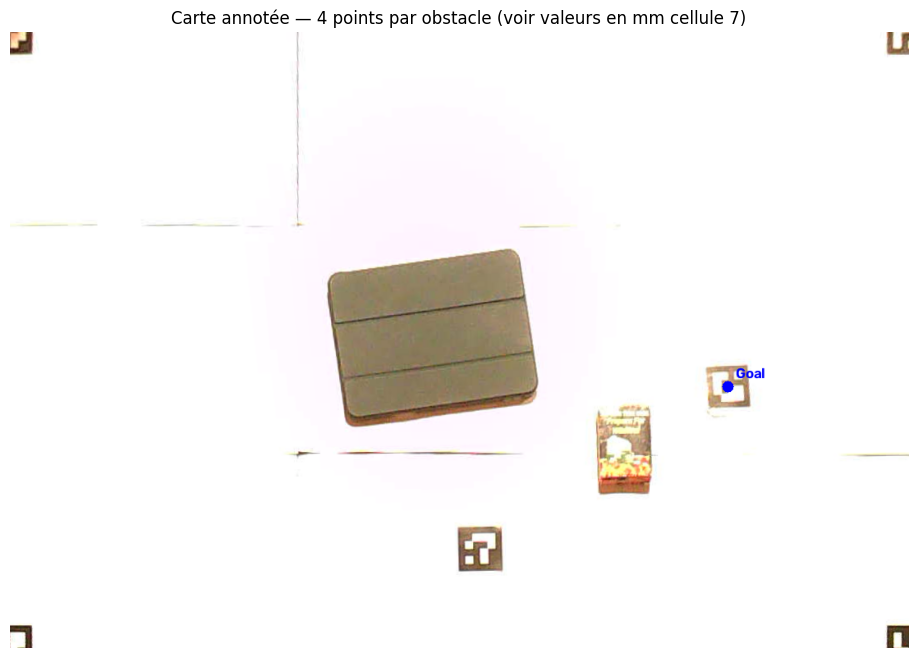

Image enregistrée : /Users/nataliedellimmagine/Documents/EPFL Semester 1/Mobile Robotics/mobile_robotics/navigation_annotated.png


In [7]:
Vision.initialize_vision(True)

In [15]:
N = 100
xs, ys, thetas = [], [], []

for _ in range(N):
    test = get_camera_pose()
    print(test)
    [x, y, theta] = get_camera_pose()
    print([x, y, theta])
    xs.append(x)
    ys.append(y)
    thetas.append(theta)
    
xs, ys, thetas = np.array(xs), np.array(ys), np.array(thetas)

print("Var for x : ", np.var(xs), " mm^2")
print("Var for y : ", np.var(ys), " mm^2")
print("Var for th : ", np.var(thetas), " rad^2")

[573.03, 120.0, -1.56]
[572.3, 120.5, -1.55]
[572.05, 120.49, -1.54]
[572.05, 120.49, -1.54]
[572.05, 120.49, -1.54]
[572.05, 120.49, -1.54]
[572.05, 120.49, -1.54]
[572.05, 120.49, -1.54]
[572.3, 120.5, -1.55]
[572.3, 120.5, -1.55]
[572.54, 120.5, -1.54]
[572.54, 120.5, -1.56]
[572.78, 120.76, -1.55]
[573.03, 120.51, -1.54]
[572.54, 120.25, -1.54]
[572.06, 120.24, -1.54]
[572.54, 120.5, -1.54]
[572.06, 119.98, -1.54]
[572.3, 120.24, -1.55]
[572.79, 119.99, -1.56]
[572.06, 120.24, -1.54]
[572.06, 119.98, -1.54]
[572.3, 120.24, -1.55]
[572.3, 120.24, -1.55]
[572.3, 120.5, -1.55]
[572.3, 119.99, -1.55]
[572.3, 120.24, -1.55]
[572.06, 120.24, -1.54]
[572.3, 120.5, -1.55]
[572.05, 120.49, -1.54]
[572.3, 120.5, -1.55]
[572.3, 119.99, -1.55]
[572.06, 120.24, -1.54]
[572.3, 120.24, -1.55]
[572.3, 119.99, -1.55]
[572.3, 120.24, -1.55]
[572.3, 120.24, -1.55]
[572.3, 120.24, -1.55]
[572.3, 120.24, -1.55]
[572.3, 120.24, -1.55]
[572.05, 120.49, -1.54]
[572.3, 120.5, -1.55]
[572.3, 120.24, -1.55]


In [16]:
xvar = [0.058650510000000045, 0.05873356000000302]
yvar = [0.05404999999999957, 0.04783459000000031]
thetavar = [0.0001133099999999999, 6.724000000000011e-05]

xvarmean, yvarmean, thetavarmean = np.mean(xvar), np.mean(yvar), np.mean(thetavar)

print("Var for x : ", np.mean(xvarmean), " mm^2")
print("Var for y : ", np.mean(yvarmean), " mm^2")
print("Var for theta : ", np.mean(thetavarmean), " rad^2")

R = np.diag([xvarmean, yvarmean, thetavarmean])

Var for x :  0.05869203500000153  mm^2
Var for y :  0.05094229499999994  mm^2
Var for theta :  9.027500000000001e-05  rad^2


In [8]:
await node.unlock()

# Test

In [6]:
async def set_speed(left, right):
    await node.set_variables({
        "motor.left.target": [int(left)],
        "motor.right.target": [int(right)]
    })
    
async def run(left, right, T):
    try:
        await set_speed(left, right)
        await client.sleep(T)          
    finally:
        await set_speed(0, 0)

async def forward(v, d): # [mm/s, mm]
    T = d/v
    SPEED_TO_MM_S = 0.335
    thymio_v = v/SPEED_TO_MM_S
    
    try:
        await set_speed(thymio_v, thymio_v)
        await client.sleep(T)          
    finally:
        await set_speed(0, 0)
        

        
async def turn(v, theta): # [rad/s, rad]

    WHEEL_BASE = 95
    SPEED_TO_MM_S = 0.335
    arc = abs(theta) * WHEEL_BASE / 2 
    T = arc / v                          
    thymio_v =  abs(v) / SPEED_TO_MM_S         
    direction = 1 if theta > 0 else -1
    try:
        await set_speed(-direction * thymio_v, direction * thymio_v)
        await client.sleep(T)
    finally:
        await set_speed(0, 0)

In [3]:
client = ClientAsync()
node = aw(client.wait_for_node())
await node.lock()

Node eeecc8f0-055d-414f-a168-42c3ba3a5cd9

In [8]:
await turn(20, 2*np.pi)

In [7]:
task = await kalman_filter.start_kalman(client, node)

await forward(20, 200)

await kalman_filter.stop_kalman(task)

t=0.3s  x=[5.3 0.  0. ]  z=[5.3 0.  0. ]  rejected=False
t=0.4s  x=[8.1 0.  0. ]  z=[8.1 0.  0. ]  rejected=False
t=0.6s  x=[11.7  0.   0. ]  z=[11.8  0.   0. ]  rejected=False
t=0.7s  x=[14.7 -0.   0. ]  z=[14.7  0.   0. ]  rejected=False
t=0.9s  x=[17.6  0.   0. ]  z=[17.6  0.   0. ]  rejected=False
t=1.1s  x=[21.1  0.   0. ]  z=[21.2  0.   0. ]  rejected=False
t=1.2s  x=[24.1  0.   0. ]  z=[24.1  0.   0. ]  rejected=False
t=1.5s  x=[30.6 -0.   0. ]  z=[30.6  0.   0. ]  rejected=False
t=1.7s  x=[33.6  0.  -0. ]  z=[33.6  0.   0. ]  rejected=False
t=1.8s  x=[36.5  0.  -0. ]  z=[36.5  0.   0. ]  rejected=False
t=2.0s  x=[40.1 -0.   0. ]  z=[40.1  0.   0. ]  rejected=False
t=2.3s  x=[45.9  0.   0. ]  z=[45.9  0.   0. ]  rejected=False
t=2.5s  x=[49.7  0.   0. ]  z=[49.7  0.   0. ]  rejected=False
t=2.6s  x=[52.8  0.   0. ]  z=[52.8  0.   0. ]  rejected=False
t=3.0s  x=[58.5 -0.   0. ]  z=[58.5  0.   0. ]  rejected=False
t=3.1s  x=[62.2 -0.   0. ]  z=[62.2  0.   0. ]  rejected=False
t=3.

In [6]:
await kalman_filter.stop_kalman(task)

In [9]:
await node.unlock()

Exception in thread Thread-4:
Traceback (most recent call last):
  File "/Users/landelain/opt/anaconda3/envs/landelenv/lib/python3.9/threading.py", line 980, in _bootstrap_inner
    self.run()
  File "/Users/landelain/opt/anaconda3/envs/landelenv/lib/python3.9/site-packages/tdmclient/tcp.py", line 73, in run
    packet = self.read_packet()
  File "/Users/landelain/opt/anaconda3/envs/landelenv/lib/python3.9/site-packages/tdmclient/tcp.py", line 66, in read_packet
    raise error
  File "/Users/landelain/opt/anaconda3/envs/landelenv/lib/python3.9/site-packages/tdmclient/tcp.py", line 59, in read_packet
    packet_len = self.read_uint32()
  File "/Users/landelain/opt/anaconda3/envs/landelenv/lib/python3.9/site-packages/tdmclient/tcp.py", line 46, in read_uint32
    b = self.io.read(4)
  File "/Users/landelain/opt/anaconda3/envs/landelenv/lib/python3.9/site-packages/tdmclient/tcp.py", line 99, in read
    return self.socket.recv(n)
ConnectionResetError: [Errno 54] Connection reset by peer
